# Predicting Student Health Risk — EDA📊

**Competition:** Kaggle Playground Series - Season 6, Episode 7
**Task:** Multi-class classification — predict `health_condition` (at-risk / unhealthy / fit) from lifestyle and physiological features
**Data:** 690,088 rows × 15 columns (7 numeric, 6 categorical, 1 id, 1 target)
**Metric:** Balanced Accuracy

# Goal of this notebook: 
Explore the data to understand target distribution, missingness patterns, and feature relationships before modeling.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e7/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e7/train.csv
/kaggle/input/competitions/playground-series-s6e7/test.csv


# Load Data

In [2]:
df = pd.read_csv('/kaggle/input/competitions/playground-series-s6e7/train.csv')

In [3]:
df.head()

,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


In [4]:
df.shape

(690088, 15)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690088 entries, 0 to 690087
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       690088 non-null  int64  
 1   health_condition         690088 non-null  object 
 2   sleep_duration           614089 non-null  float64
 3   heart_rate               682255 non-null  float64
 4   bmi                      676190 non-null  float64
 5   calorie_expenditure      637235 non-null  float64
 6   step_count               676172 non-null  float64
 7   exercise_duration        683187 non-null  float64
 8   water_intake             646611 non-null  float64
 9   diet_type                683187 non-null  object 
 10  stress_level             607277 non-null  object 
 11  sleep_quality            631757 non-null  object 
 12  physical_activity_level  653467 non-null  object 
 13  smoking_alcohol          661506 non-null  object 
 14  gend

In [6]:
df.isnull().sum()

id                             0
health_condition               0
sleep_duration             75999
heart_rate                  7833
bmi                        13898
calorie_expenditure        52853
step_count                 13916
exercise_duration           6901
water_intake               43477
diet_type                   6901
stress_level               82811
sleep_quality              58331
physical_activity_level    36621
smoking_alcohol            28582
gender                     21373
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

# EDA📊

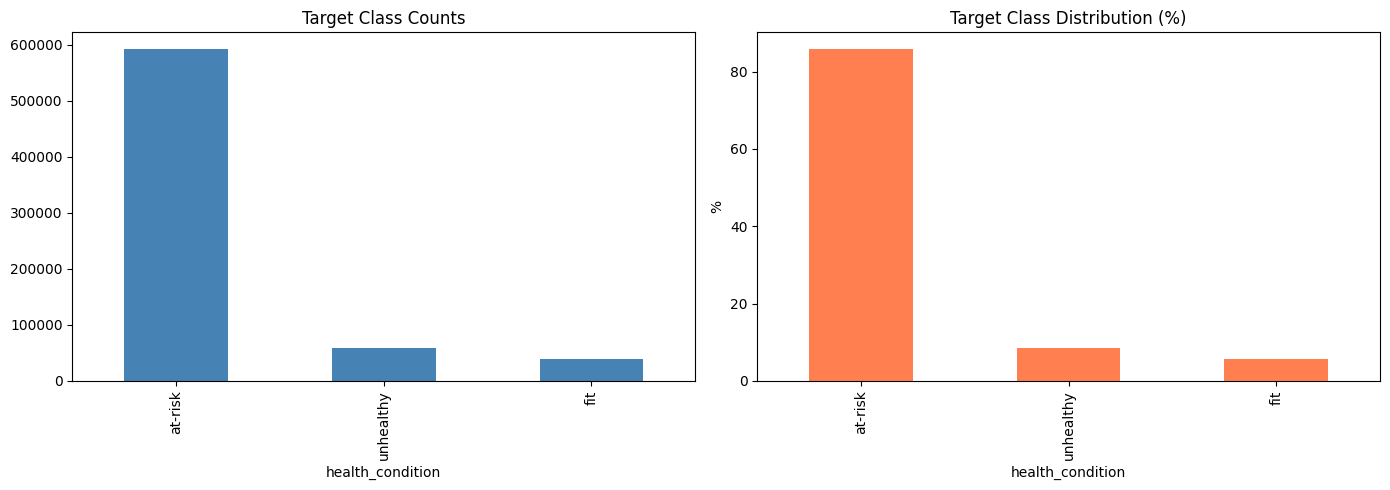

health_condition
at-risk      592561
unhealthy     57724
fit           39803
Name: count, dtype: int64

Imbalance ratio (max/min): 14.89


In [8]:
target_counts = df['health_condition'].value_counts()
target_pct = df['health_condition'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
target_counts.plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Target Class Counts')
ax[0].set_xlabel('health_condition')

target_pct.plot(kind='bar', ax=ax[1], color='coral')
ax[1].set_title('Target Class Distribution (%)')
ax[1].set_ylabel('%')

plt.tight_layout()
plt.show()

print(target_counts)
print(f"\nImbalance ratio (max/min): {target_counts.max() / target_counts.min():.2f}")

                         missing_count  missing_pct
stress_level                     82811    12.000064
sleep_duration                   75999    11.012943
sleep_quality                    58331     8.452690
calorie_expenditure              52853     7.658878
water_intake                     43477     6.300211
physical_activity_level          36621     5.306715
smoking_alcohol                  28582     4.141791
gender                           21373     3.097141
step_count                       13916     2.016554
bmi                              13898     2.013946
heart_rate                        7833     1.135073
diet_type                         6901     1.000017
exercise_duration                 6901     1.000017


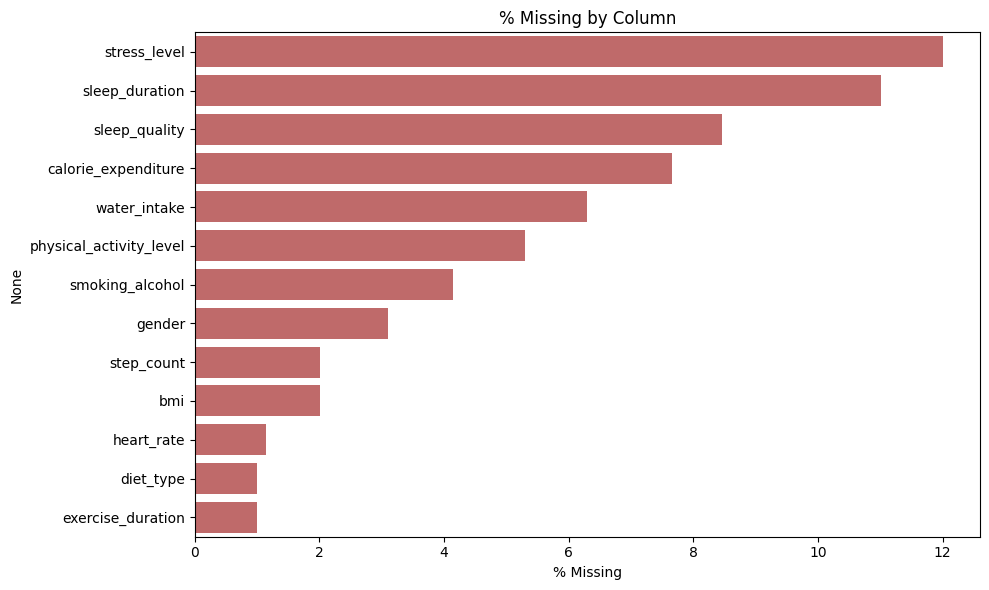

In [9]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df = missing_df[missing_df['missing_count'] > 0]
print(missing_df)

plt.figure(figsize=(10, 6))
sns.barplot(x=missing_df['missing_pct'], y=missing_df.index, color='indianred')
plt.title('% Missing by Column')
plt.xlabel('% Missing')
plt.tight_layout()
plt.show()

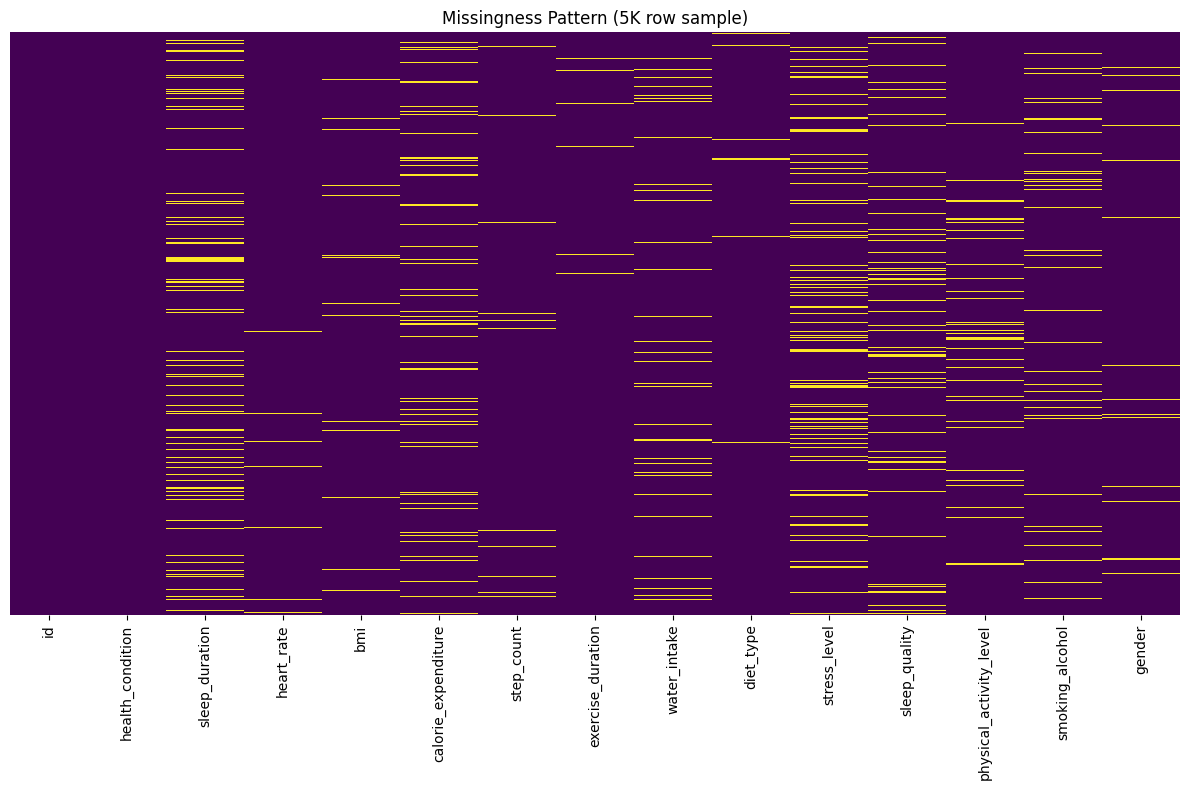

In [10]:
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(12, 8))
sns.heatmap(sample.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missingness Pattern (5K row sample)')
plt.tight_layout()
plt.show()

In [11]:
cols_with_na = missing_df.index.tolist()

for col in cols_with_na:
    df[f'{col}_was_missing'] = df[col].isnull().astype(int)

missing_vs_target = df.groupby('health_condition')[[f'{c}_was_missing' for c in cols_with_na]].mean()
missing_vs_target

,stress_level_was_missing,sleep_duration_was_missing,sleep_quality_was_missing,calorie_expenditure_was_missing,water_intake_was_missing,physical_activity_level_was_missing,smoking_alcohol_was_missing,gender_was_missing,step_count_was_missing,bmi_was_missing,heart_rate_was_missing,diet_type_was_missing,exercise_duration_was_missing
health_condition,,,,,,,,,,,,,
at-risk,0.120038,0.110213,0.084621,0.076532,0.062740,0.053114,0.041327,0.030957,0.020246,0.020845,0.011511,0.010104,0.009910
fit,0.119564,0.109439,0.085270,0.077004,0.063412,0.052634,0.041404,0.029897,0.019923,0.028616,0.010879,0.008818,0.010477
unhealthy,0.119915,0.109746,0.083050,0.076883,0.065415,0.052890,0.042357,0.031858,0.019507,0.007051,0.010030,0.009753,0.010602


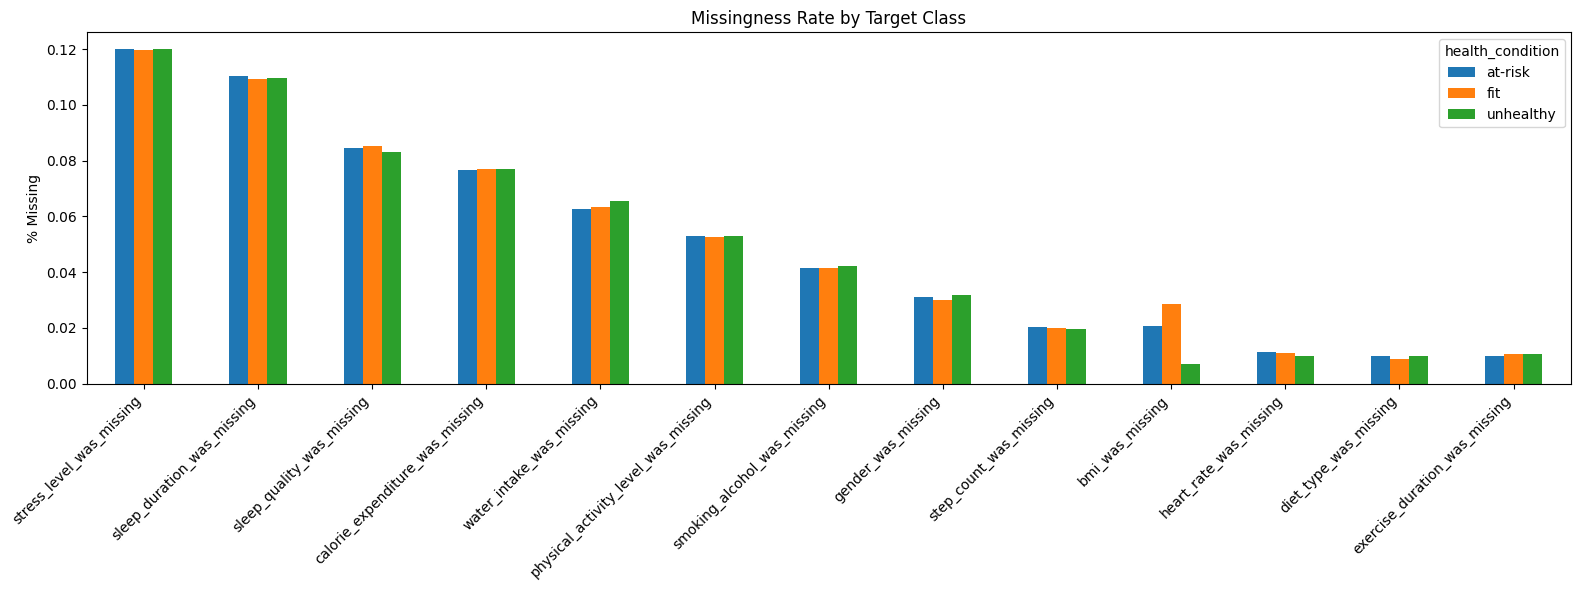

In [12]:
missing_vs_target.T.plot(kind='bar', figsize=(16, 6))
plt.title('Missingness Rate by Target Class')
plt.ylabel('% Missing')
plt.xticks(rotation=45, ha='right')
plt.legend(title='health_condition', bbox_to_anchor=(1.001, 1))
plt.tight_layout()
plt.show()

In [13]:
missing_flag_cols = [col for col in df.columns if col.endswith('_was_missing')]
df = df.drop(columns=missing_flag_cols)
print(f"Dropped: {missing_flag_cols}")
print(df.shape)

Dropped: ['stress_level_was_missing', 'sleep_duration_was_missing', 'sleep_quality_was_missing', 'calorie_expenditure_was_missing', 'water_intake_was_missing', 'physical_activity_level_was_missing', 'smoking_alcohol_was_missing', 'gender_was_missing', 'step_count_was_missing', 'bmi_was_missing', 'heart_rate_was_missing', 'diet_type_was_missing', 'exercise_duration_was_missing']
(690088, 15)


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690088 entries, 0 to 690087
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       690088 non-null  int64  
 1   health_condition         690088 non-null  object 
 2   sleep_duration           614089 non-null  float64
 3   heart_rate               682255 non-null  float64
 4   bmi                      676190 non-null  float64
 5   calorie_expenditure      637235 non-null  float64
 6   step_count               676172 non-null  float64
 7   exercise_duration        683187 non-null  float64
 8   water_intake             646611 non-null  float64
 9   diet_type                683187 non-null  object 
 10  stress_level             607277 non-null  object 
 11  sleep_quality            631757 non-null  object 
 12  physical_activity_level  653467 non-null  object 
 13  smoking_alcohol          661506 non-null  object 
 14  gend

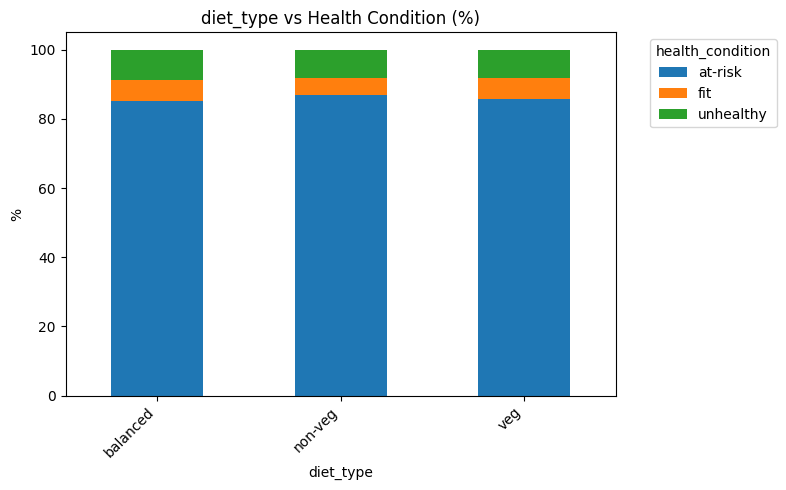

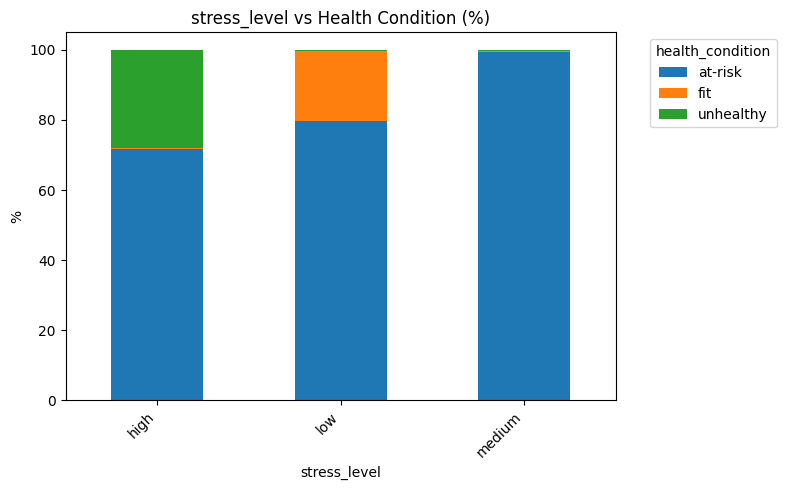

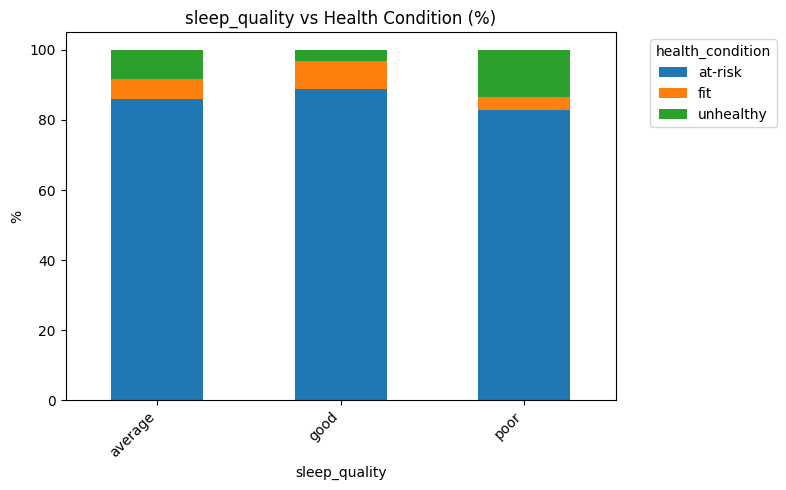

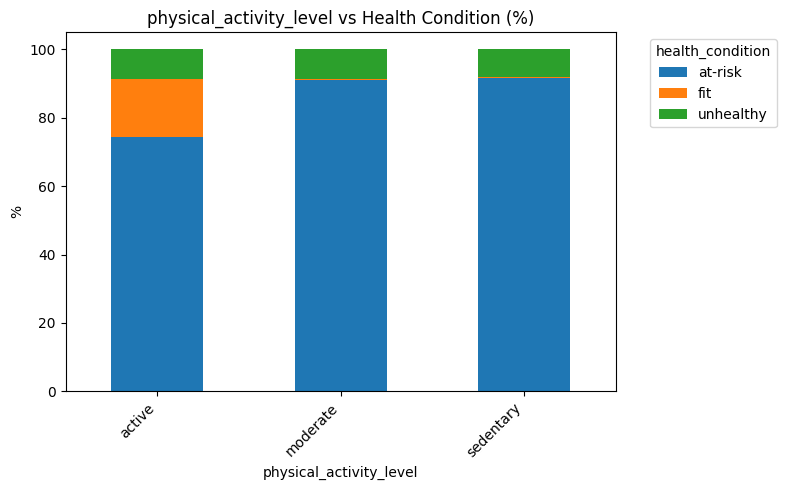

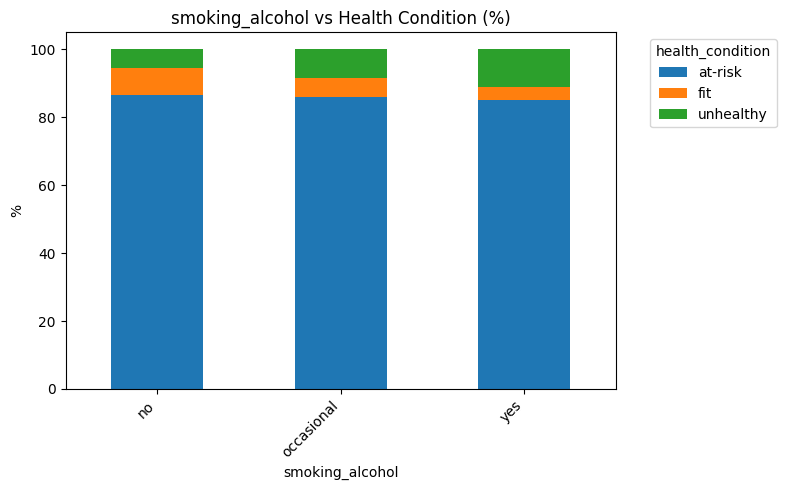

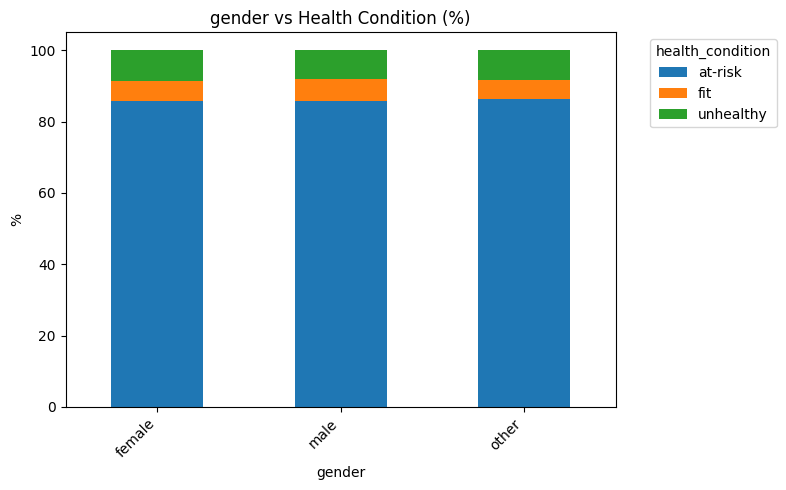

In [15]:
categorical_cols = ['diet_type', 'stress_level', 'sleep_quality', 
                     'physical_activity_level', 'smoking_alcohol', 'gender']

for col in categorical_cols:
    ct = pd.crosstab(df[col], df['health_condition'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, figsize=(8, 5))
    plt.title(f'{col} vs Health Condition (%)')
    plt.ylabel('%')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='health_condition', bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.show()

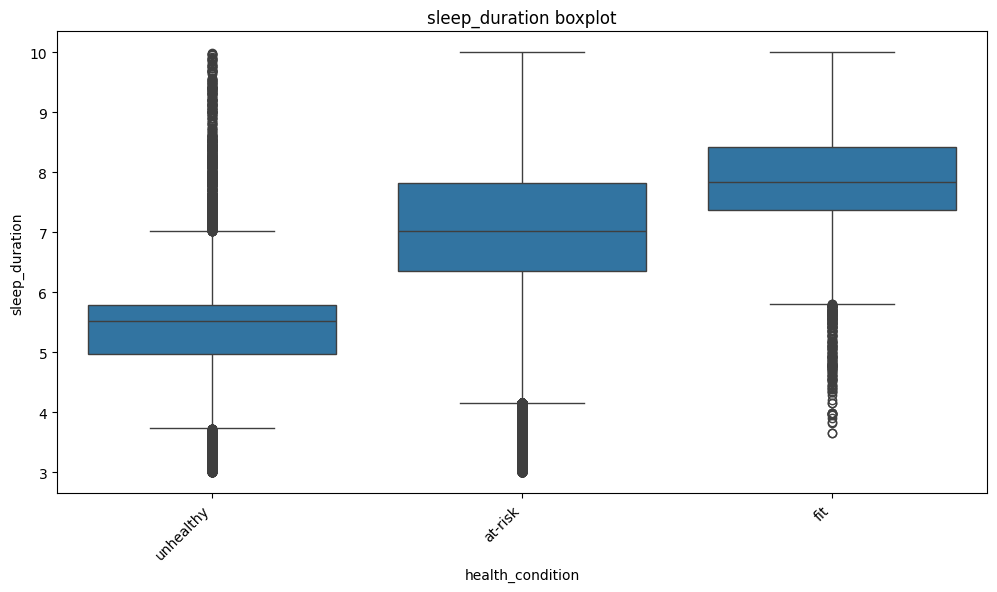

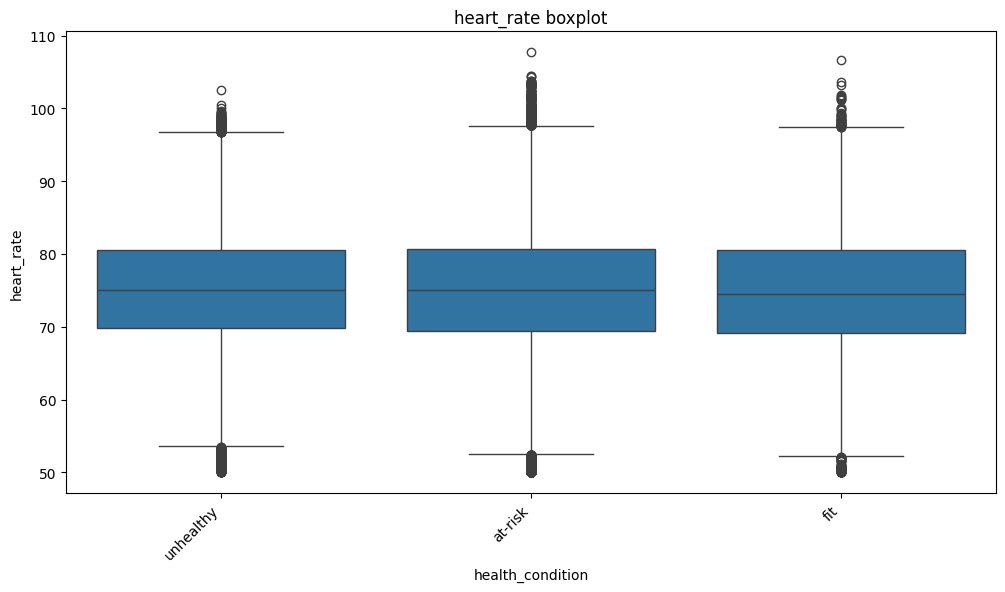

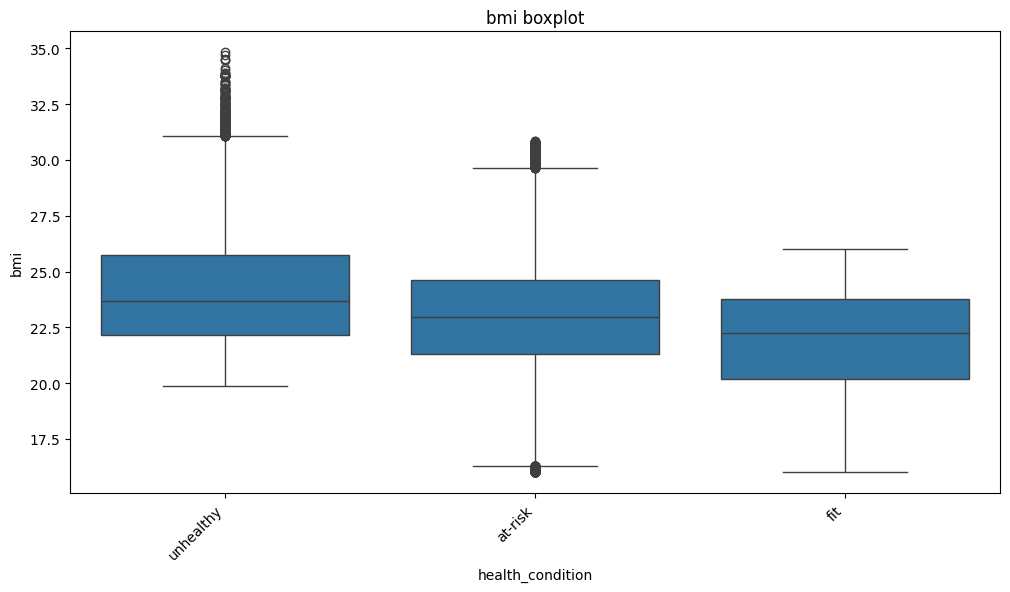

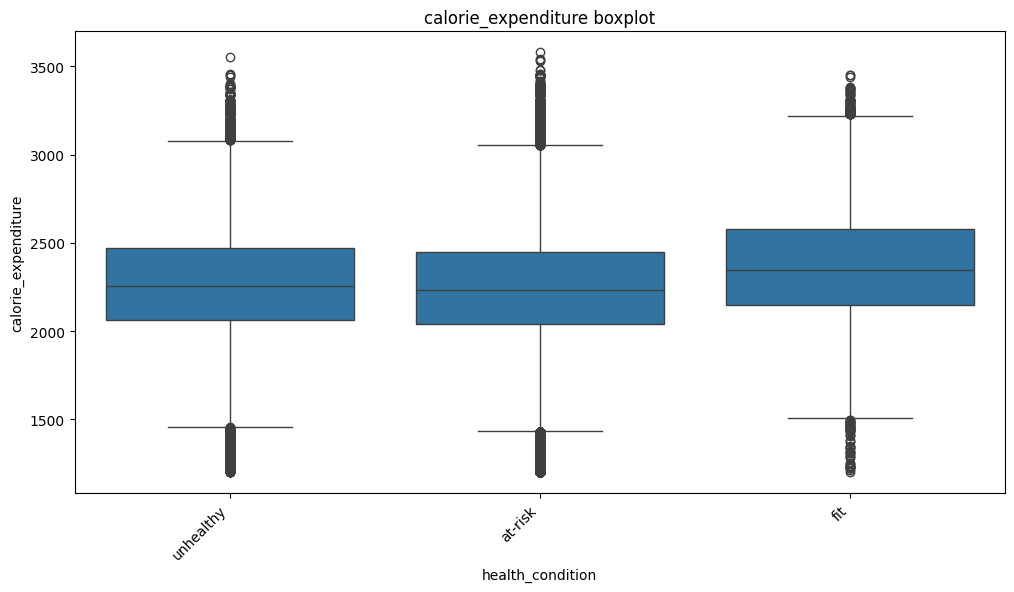

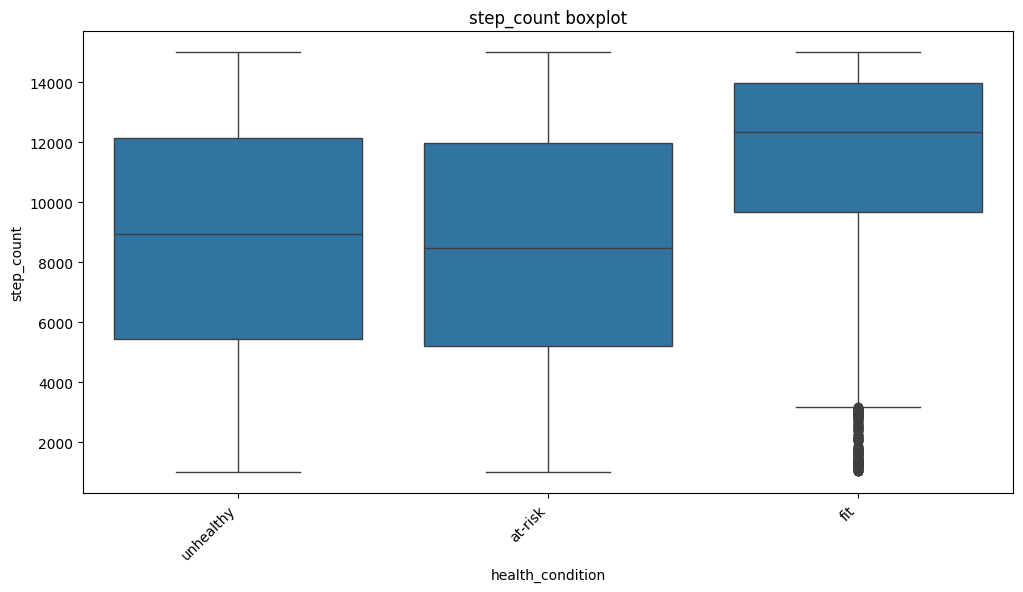

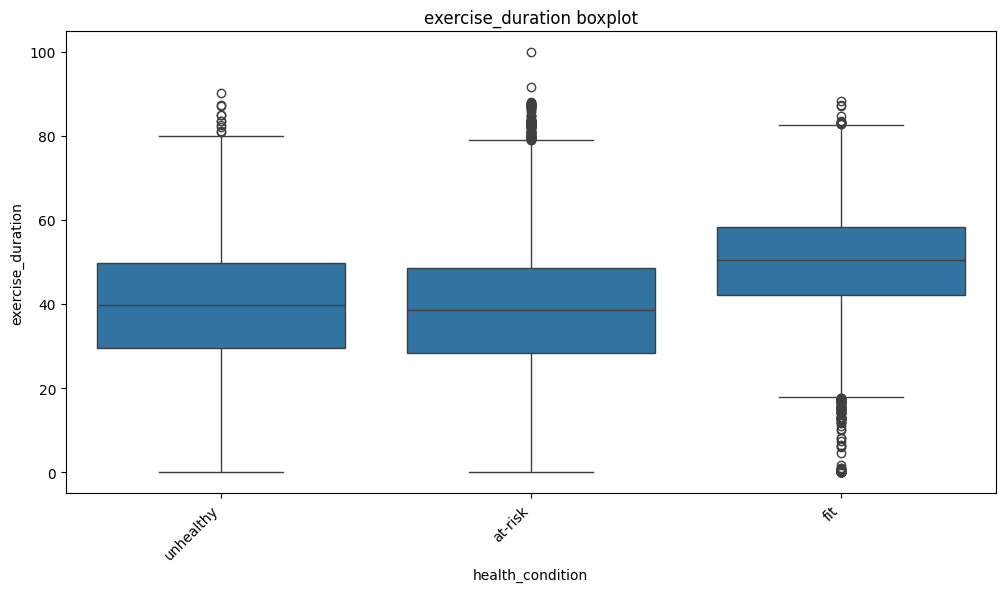

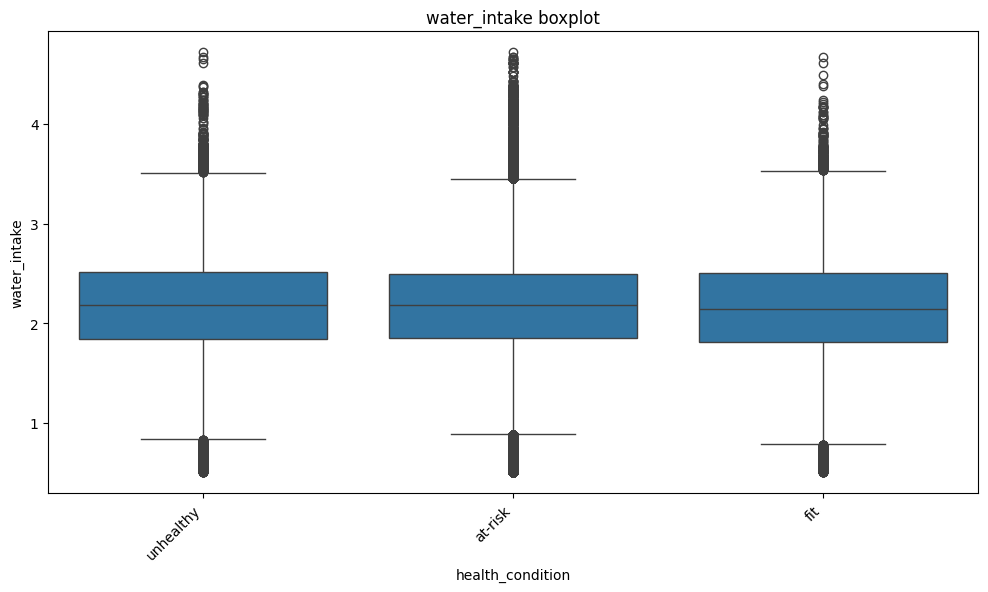

In [16]:
numerical_cols = ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake']

for i in numerical_cols:

    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x='health_condition', y=i)
    plt.title(f'{i} boxplot')
    plt.xticks(rotation=45, ha='right')
    plt.show()

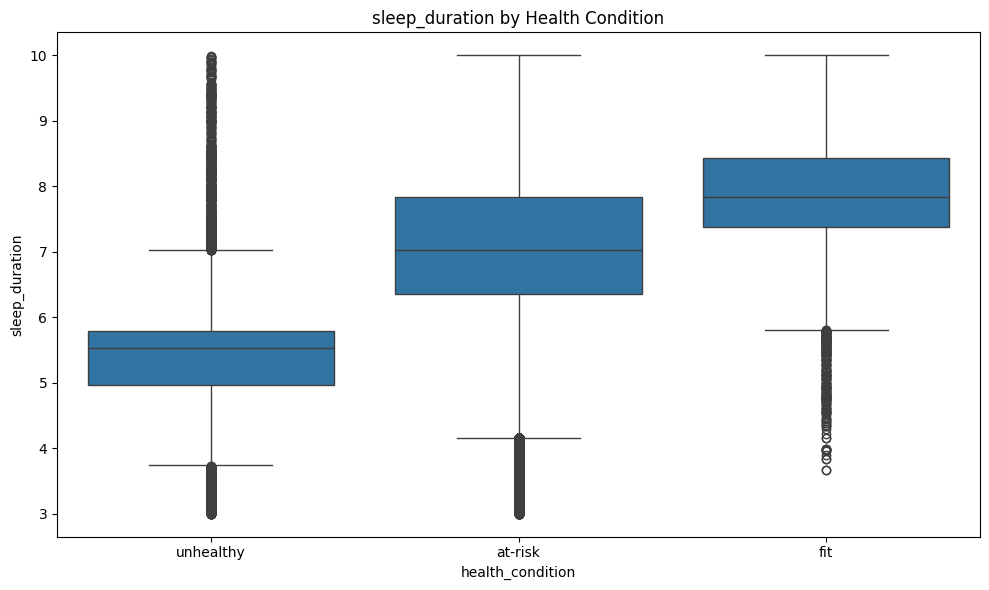

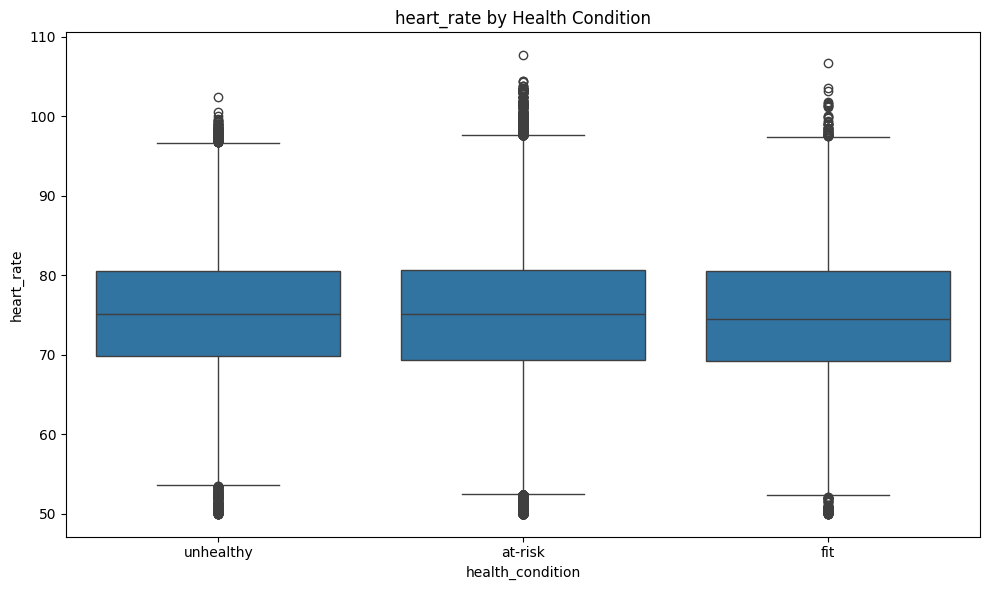

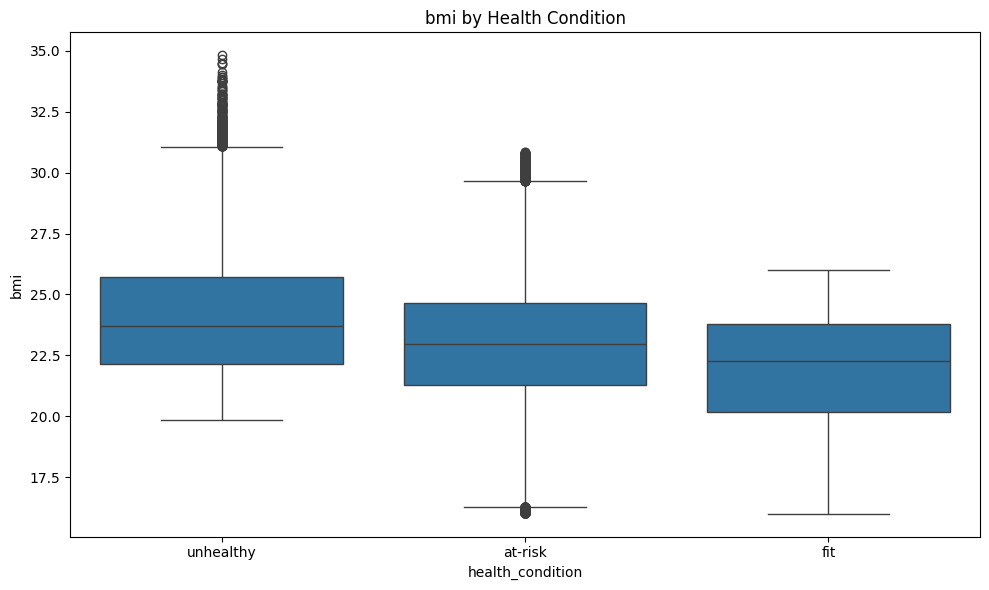

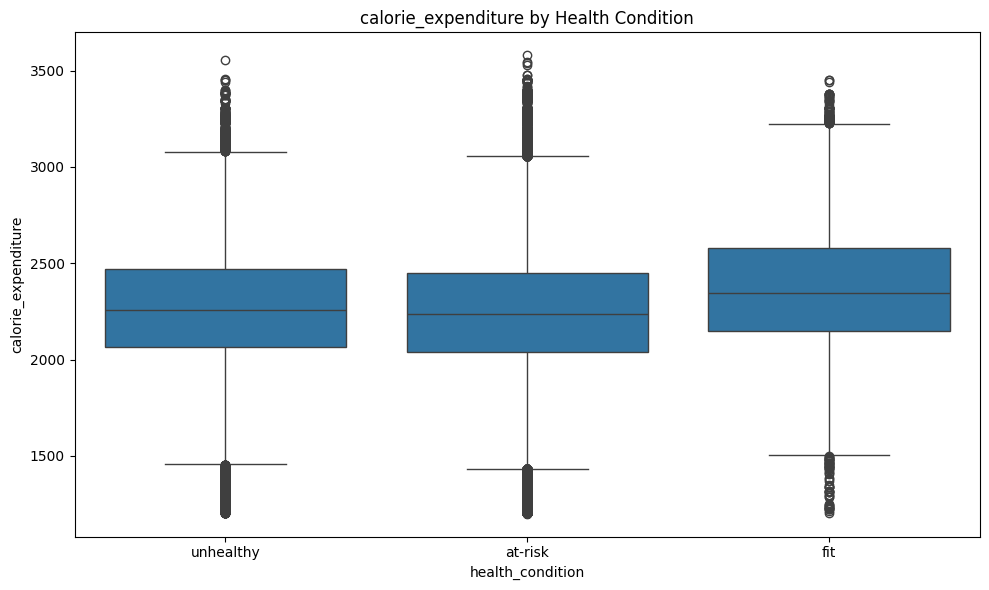

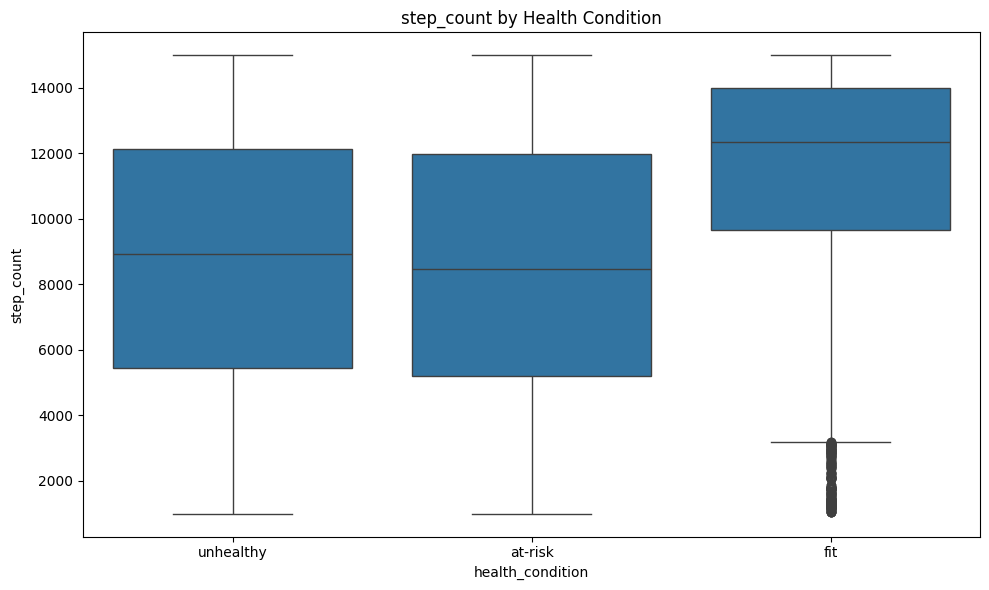

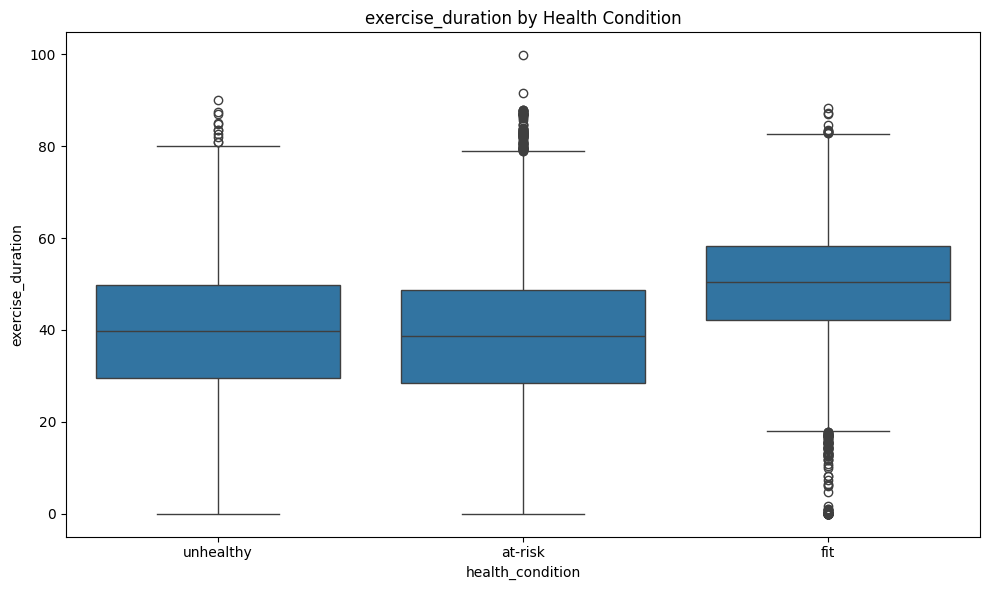

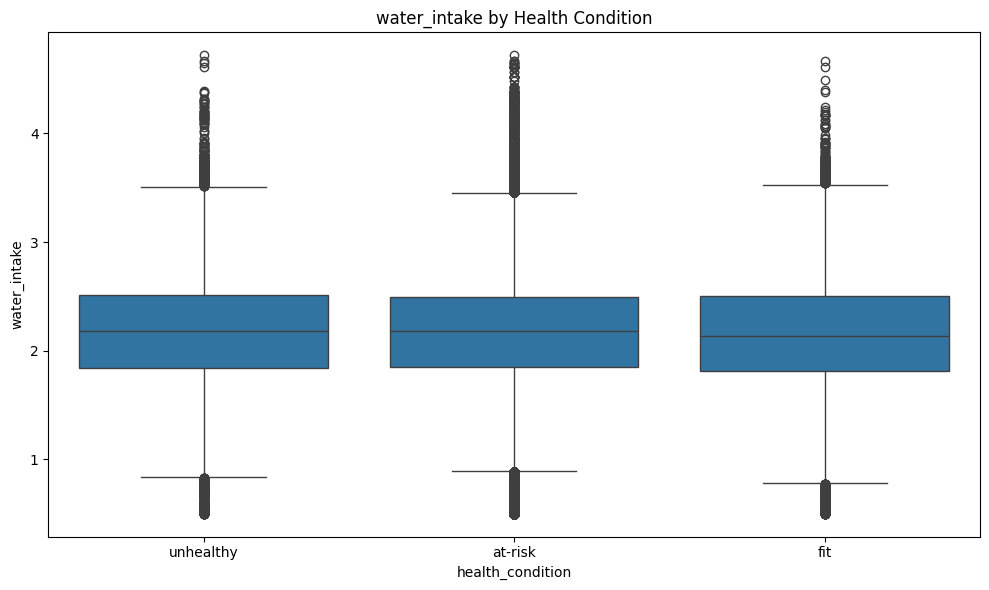

In [17]:
numerical_cols = ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 
                   'step_count', 'exercise_duration', 'water_intake']

for i in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, x='health_condition', y=i)
    plt.title(f'{i} by Health Condition')
    plt.tight_layout()
    plt.show()

In [18]:
df.groupby('health_condition')[numerical_cols].agg(['mean', 'median'])

sleep_duration        heart_rate               bmi         \
                           mean median       mean median       mean median   
health_condition                                                             
at-risk                7.086467   7.03  75.100534   75.1  22.949591  22.96   
fit                    7.954311   7.84  74.803742   74.5  21.828544  22.25   
unhealthy              5.366118   5.53  75.256903   75.1  24.122660  23.70   

                 calorie_expenditure            step_count           \
                                mean  median          mean   median   
health_condition                                                      
at-risk                  2214.943466  2235.0   8406.705910   8483.0   
fit                      2363.992052  2345.0  11651.307024  12342.5   
unhealthy                2245.420223  2255.0   8670.234090   8941.5   

                 exercise_duration        water_intake         
                              mean median         mean median  
health_condition                                               
at-risk                  37.964960   38.6     2.189130   2.18  
fit                      50.042381   50.5     2.179176   2.14  
unhealthy                39.044280   39.7     2.188961   2.18

In [19]:
df[numerical_cols].describe()

,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake
count,614089.000000,682255.000000,676190.000000,637235.000000,676172.000000,683187.000000,646611.000000
mean,6.992597,75.096504,22.984925,2226.084931,8615.953050,38.751456,2.188542
std,1.215407,8.175106,2.481787,347.532098,3929.399831,14.742189,0.518489
min,3.000000,50.000000,16.000000,1200.000000,1002.000000,0.000000,0.500000
25%,6.160000,69.400000,21.320000,2053.000000,5389.000000,29.200000,1.840000
50%,6.990000,75.100000,22.990000,2241.000000,8856.000000,39.400000,2.170000
75%,7.810000,80.700000,24.660000,2456.000000,12114.000000,49.400000,2.500000
max,10.000000,107.700000,34.820000,3580.000000,14999.000000,99.800000,4.720000


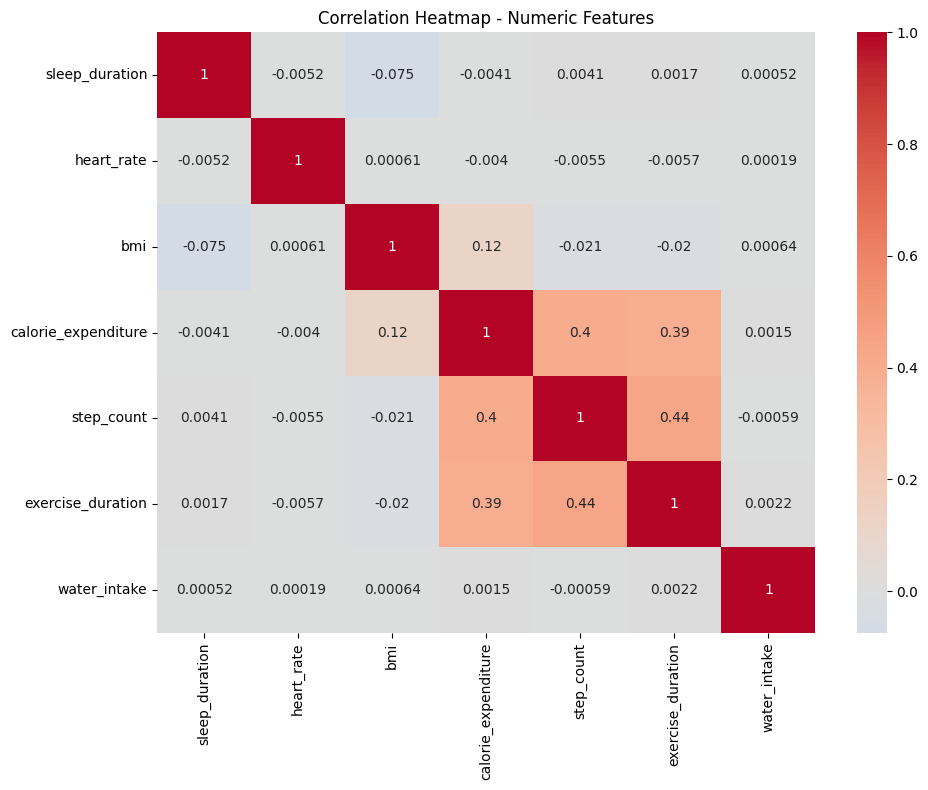


=== sleep_quality ===
health_condition  at-risk  fit  unhealthy
sleep_quality                            
average              85.9  5.7        8.3
good                 88.8  8.2        3.0
poor                 83.0  3.5       13.6

=== physical_activity_level ===
health_condition         at-risk   fit  unhealthy
physical_activity_level                          
active                      74.3  17.2        8.5
moderate                    91.1   0.3        8.5
sedentary                   91.7   0.2        8.0

=== smoking_alcohol ===
health_condition  at-risk  fit  unhealthy
smoking_alcohol                          
no                   86.7  7.9        5.5
occasional           85.9  5.8        8.4
yes                  85.1  3.7       11.2

=== gender ===
health_condition  at-risk  fit  unhealthy
gender                                   
female               85.7  5.7        8.6
male                 85.7  6.3        8.0
other                86.2  5.3        8.5


In [20]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap - Numeric Features')
plt.tight_layout()
plt.show()

remaining_cats = ['sleep_quality', 'physical_activity_level', 'smoking_alcohol', 'gender']
for col in remaining_cats:
    print(f"\n=== {col} ===")
    print((pd.crosstab(df[col], df['health_condition'], normalize='index') * 100).round(1))

## Key Findings

**Target distribution:** Severely imbalanced — `at-risk` 85.9%, `unhealthy` 8.4%, `fit` 5.8% (14.9x imbalance ratio). This explains the use of balanced accuracy as the evaluation metric and requires stratified CV and class weighting during modeling.

**Missingness:** Present across most features (2-12% missing), but tested against the target and found no meaningful relationship — missingness is likely MCAR. Standard imputation should be safe without introducing bias.

**Numeric features:** Four features show real separation across classes — `sleep_duration` (unhealthy < at-risk < fit), `step_count` and `exercise_duration` (fit notably higher than the other two classes), and `bmi` (unhealthy highest, fit lowest). Three features show negligible separation — `heart_rate`, `calorie_expenditure`, `water_intake` — and are unlikely to be strong predictors on their own.

**Correlation:** Mild-to-moderate correlation among activity-related features (`step_count`, `exercise_duration`, `calorie_expenditure`, r≈0.4), but nothing severe enough to warrant dropping any feature.

**Categorical features (partial):** `stress_level` shows a strong, intuitive relationship with the target (medium stress → near-universal at-risk; high stress → shifts toward unhealthy; low stress → shifts toward fit). `diet_type` shows no meaningful relationship with the target.